# Lab 2: Overfitting and Lasso Regression

Two parts:

1. **Polynomial regression on synthetic data**, to see overfitting happen and measure it with R² on a held-out test set.
2. **Lasso (L1) regression** to predict daily bike rentals from weather and calendar features.

## 1. Polynomial regression and overfitting

Synthetic data: purchase amount falls as page load time rises, plus noise.

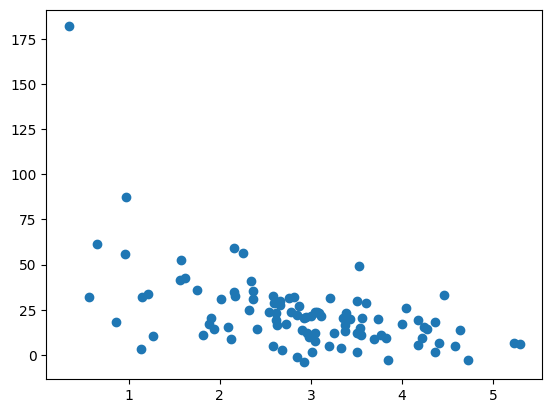

In [1]:
%matplotlib inline
import numpy as np
from pylab import *

np.random.seed(2)

pageSpeeds = np.random.normal(3.0, 1.0, 100)
purchaseAmount = np.random.normal(50.0, 30.0, 100) / pageSpeeds

scatter(pageSpeeds, purchaseAmount)

Split 80% train / 20% test. The data is random, so slicing is a fair split.

In [2]:
trainX = pageSpeeds[:80]
testX = pageSpeeds[80:]

trainY = purchaseAmount[:80]
testY = purchaseAmount[80:]

Fit an 8th-degree polynomial, which is far more flexible than the data needs.

In [3]:
x = np.array(trainX)
y = np.array(trainY)

p4 = np.poly1d(np.polyfit(x, y, 8))

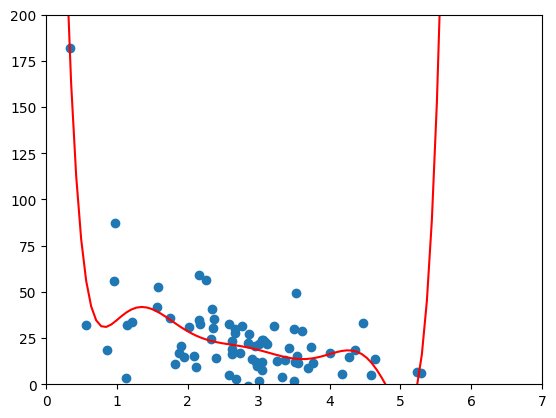

In [4]:
import matplotlib.pyplot as plt

xp = np.linspace(0, 7, 100)
axes = plt.axes()
axes.set_xlim([0, 7])
axes.set_ylim([0, 200])
plt.scatter(x, y)
plt.plot(xp, p4(xp), c='r')
plt.show()

The same curve against the unseen test data:

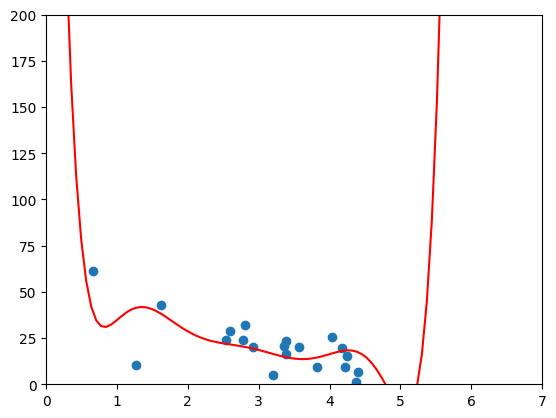

In [5]:
testx = np.array(testX)
testy = np.array(testY)

axes = plt.axes()
axes.set_xlim([0, 7])
axes.set_ylim([0, 200])
plt.scatter(testx, testy)
plt.plot(xp, p4(xp), c='r')
plt.show()

R² on test vs training data. A large gap means the model memorised the training set.

In [6]:
from sklearn.metrics import r2_score

print(r2_score(testy, p4(testx)))
print(r2_score(np.array(trainY), p4(np.array(trainX))))

0.3001816861251314
0.6427069514691321


### Activity: which polynomial degree works best?

In [7]:
for degree in range(1, 9):
    p = np.poly1d(np.polyfit(x, y, degree))
    print(degree, r2_score(testy, p(testx)))

1 0.4225414067989236
2 0.2935031793784675
3 0.27274311475200375
4 0.39362692609902417
5 0.5040723897194309
6 0.6050119470355094
7 0.5461451452852593
8 0.3001816861251314


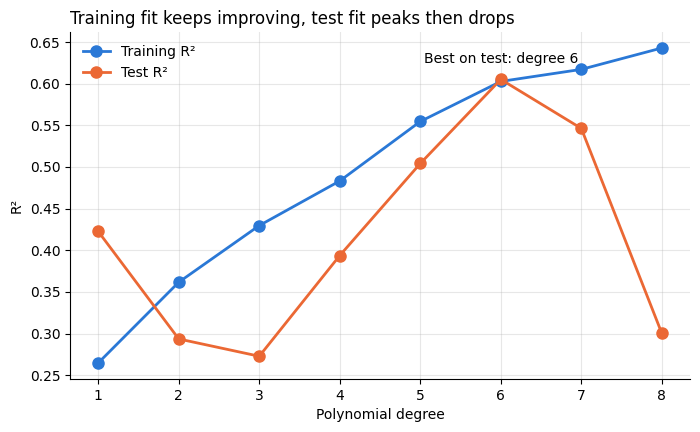

In [8]:
degrees = range(1, 9)
test_r2 = [r2_score(testy, np.poly1d(np.polyfit(x, y, d))(testx)) for d in degrees]
train_r2 = [r2_score(y, np.poly1d(np.polyfit(x, y, d))(x)) for d in degrees]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(degrees, train_r2, marker='o', markersize=8, linewidth=2, color='#2a78d6', label='Training R²')
ax.plot(degrees, test_r2, marker='o', markersize=8, linewidth=2, color='#eb6834', label='Test R²')
best = int(np.argmax(test_r2)) + 1
ax.annotate(f'Best on test: degree {best}', (best, max(test_r2)), textcoords='offset points', xytext=(0, 12), ha='center')
ax.set_xlabel('Polynomial degree')
ax.set_ylabel('R²')
ax.set_title('Training fit keeps improving, test fit peaks then drops', loc='left')
ax.grid(alpha=0.3)
ax.spines[['top', 'right']].set_visible(False)
ax.legend(frameon=False)
plt.show()

**Answer:** degree 6 gives the best test R² (about 0.61). Training R² keeps rising with degree, but beyond 6 the test score falls: the extra flexibility fits noise, not the underlying pattern. That gap between training and test performance is overfitting.

## 2. Lasso regression on bike rental data

Predict `cnt` (daily bike rentals) from temperature, humidity, wind speed and one-hot encoded season, year, month, weather and holiday.

In [9]:
import os
import pandas

DATA = pandas.read_csv("Data.csv")
DATA

X = DATA.drop(['cnt'], axis=1)
Y = DATA['cnt']

Split with scikit-learn's `train_test_split` (80/20).

In [10]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=42)

Fit Lasso and evaluate on the test set.

In [11]:
from sklearn.linear_model import Lasso
from sklearn.metrics import r2_score, mean_squared_error

model = Lasso(alpha=1.0)
model.fit(X_train, Y_train)

predictions = model.predict(X_test)

print("R2:", r2_score(Y_test, predictions))
print("MSE:", mean_squared_error(Y_test, predictions))

print(pandas.Series(model.coef_, index=X.columns))

R2: 0.8375100167981674
MSE: 611998.265366054
temp            4886.153350
hum            -1746.901760
windspeed      -2403.913283
season_1       -1032.601472
season_2           0.000000
season_3        -134.661819
season_4         584.421468
yr_0           -2002.549229
yr_1               0.000000
mnth_1          -181.138896
mnth_10          297.255020
mnth_11         -389.503717
mnth_12         -348.069765
mnth_2           -47.494789
mnth_3           258.905339
mnth_4            23.543896
mnth_5           299.982493
mnth_6             0.000000
mnth_7          -474.607754
mnth_8            -0.000000
mnth_9           588.729922
weathersit_1     419.240001
weathersit_2       0.000000
weathersit_3   -1209.094831
holiday_0        583.509158
holiday_1         -0.000000
dtype: float64


### Which features did Lasso remove?

The L1 penalty pushes unhelpful coefficients to exactly zero, so Lasso also performs feature selection.

In [12]:
coefs = pandas.Series(model.coef_, index=X.columns)
print('Features set to zero:', list(coefs[coefs == 0].index))
print(f'{(coefs != 0).sum()} of {len(coefs)} features kept')

Features set to zero: ['season_2', 'yr_1', 'mnth_6', 'mnth_8', 'weathersit_2', 'holiday_1']
20 of 26 features kept


### Comparison with ordinary linear regression

In [13]:
from sklearn.linear_model import LinearRegression

linear = LinearRegression().fit(X_train, Y_train)
linear_pred = linear.predict(X_test)

comparison = pandas.DataFrame({
    'R²': [r2_score(Y_test, predictions), r2_score(Y_test, linear_pred)],
    'RMSE (rentals/day)': [mean_squared_error(Y_test, predictions) ** 0.5, mean_squared_error(Y_test, linear_pred) ** 0.5],
}, index=['Lasso (alpha=1)', 'Linear regression'])
comparison.round(3)

,R²,RMSE (rentals/day)
Lasso (alpha=1),0.838,782.303
Linear regression,0.837,782.759


**Findings:** Lasso explains about 84% of the variation in daily rentals (R² ≈ 0.84, RMSE ≈ 782 rentals/day). Temperature has by far the largest positive effect, while humidity and wind speed reduce rentals. Lasso set 6 of the 26 coefficients to exactly zero, including redundant one-hot columns such as `yr_1` and `holiday_1`, and still matched plain linear regression's accuracy with fewer features.